# 02 · Vingt ans de prix à la pompe

Le notebook 01 décrivait une photo, celle du 19 octobre 2026. Celui-ci remonte le temps : chaque changement de prix de chaque station depuis janvier 2007, soit plus de 60 millions de lignes.

**Questions**
1. Comment les prix ont-ils évolué depuis 2007, et où se situe 2026 ?
2. Le gazole est-il toujours moins cher que l'essence ?
3. Les écarts entre stations se creusent-ils, et d'où viennent les prix identiques de 2026 ?
4. Les écarts entre départements sont-ils stables ?
5. Y a-t-il un bon jour pour faire le plein ?

Tous les prix sont en **euros courants** (non corrigés de l'inflation). Les fichiers annuels viennent de la release `historique` du dépôt (`gh release download historique --dir data/historique`) ; la première cellule affiche le commit qui les a produits. Les chiffres cités dans le texte sont recalculés et vérifiés par la dernière cellule.

In [1]:
from datetime import date, timedelta
import json
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import TwoSlopeNorm

from carburants import analyse

HISTORIQUE = Path("../data/historique")
FIGURES = Path("../rapports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
PRINCIPAUX = ["Gazole", "SP95", "E10", "SP98"]
# Les prix fixés avant 2007 sont invisibles : les premières semaines ne couvrent que la moitié des stations
DEBUT = date(2007, 3, 5)
chiffres = {}

pl.Config.set_tbl_rows(25)
pl.Config.set_tbl_width_chars(140)

BLEU, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6"
TEXTE, TEXTE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
COULEURS = {"Gazole": BLEU, "SP95": ORANGE, "E10": AQUA, "SP98": VIOLET}
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "savefig.facecolor": FOND,
    "axes.edgecolor": GRILLE, "axes.labelcolor": TEXTE_2, "axes.titlecolor": TEXTE,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "xtick.color": TEXTE_2, "ytick.color": TEXTE_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def sauver(fig, nom):
    fig.savefig(FIGURES / f"{nom}.png")

def axe_annees(ax, pas=2):
    ax.xaxis.set_major_locator(mdates.YearLocator(pas))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fiches = [json.loads(f.read_text()) for f in sorted(HISTORIQUE.glob("prix_*.json"))]
print("polars", pl.__version__)
print("Fichiers produits par le(s) commit(s) :", sorted({f["commit"][:7] for f in fiches}))

polars 2.0.0
Fichiers produits par le(s) commit(s) : ['c1aee7f']


## Chargement et série hebdomadaire

L'historique liste les changements de prix, pas les prix en vigueur : une station qui garde le même prix trois semaines n'apparaît qu'une fois. On reconstruit donc une série **hebdomadaire** par station et par carburant : le dernier prix publié dans la semaine, prolongé au plus trois semaines s'il ne change pas (au-delà, la station a probablement cessé de déclarer). La semaine lisse aussi un défaut des fichiers 2015-2016, dont les minutes ne sont pas fiables. Les statistiques commencent en mars 2007 et n'utilisent que les semaines où au moins 500 stations vendent le carburant.

In [2]:
prix = analyse.charger_historique(HISTORIQUE)
resume = prix.group_by(annee=pl.col("maj").dt.year()).agg(lignes=pl.len(), stations=pl.col("station_id").n_unique()).sort("annee").collect()
print(f"{resume['lignes'].sum():,} prix publiés de {resume['annee'].min()} à {resume['annee'].max()}")
resume

64,065,362 prix publiés de 2007 à 2026


annee,lignes,stations
i32,u32,u32
2007,865796,7356
2008,1419376,7789
2009,1396403,8155
2010,1442915,8405
2011,1611215,8653
2012,1902921,9018
2013,2146743,9386
2014,2197941,9731
2015,3300813,9718


In [3]:
hebdo = analyse.prix_hebdo(prix.filter(pl.col("carburant").is_in(PRINCIPAUX)))
stats = analyse.statistiques_hebdo(hebdo).filter(pl.col("semaine") >= DEBUT, pl.col("stations") >= 500)
part_prolongee = hebdo.group_by("carburant").agg(prolongees=(~pl.col("publie")).mean() * 100).sort("carburant")
chiffres["prolongees_min"], chiffres["prolongees_max"] = part_prolongee["prolongees"].min(), part_prolongee["prolongees"].max()
print(f"{hebdo.height:,} prix hebdomadaires")
part_prolongee

23,914,682 prix hebdomadaires


carburant,prolongees
str,f64
"""E10""",17.611545
"""Gazole""",21.307871
"""SP95""",29.032752
"""SP98""",22.989297


## 1. Vingt ans de prix

In [4]:
gazole = stats.filter(carburant="Gazole")
record = gazole.sort("mediane").row(-1, named=True)
pic_2022 = gazole.filter(pl.col("semaine").dt.year() == 2022).sort("mediane").row(-1, named=True)
chiffres["record"], chiffres["pic_2022"] = record["mediane"], pic_2022["mediane"]
chiffres["avant_hausse"] = gazole.filter(semaine=date(2026, 2, 23))["mediane"].item()
chiffres["apres_hausse"] = gazole.filter(semaine=date(2026, 3, 30))["mediane"].item()
annuel = (
    stats.with_columns(annee=pl.col("semaine").dt.year())
    .group_by("annee", "carburant").agg(pl.col("mediane").mean().round(3))
    .pivot(on="carburant", index="annee", values="mediane").sort("annee")
    .select("annee", *PRINCIPAUX)
)
for annee in [2007, 2022, 2026]:
    chiffres[f"gazole_{annee}"] = annuel.filter(annee=annee)["Gazole"].item()
print(f"Record : {record['mediane']:.3f} € la semaine du {record['semaine']}, pic de 2022 : {pic_2022['mediane']:.3f} € ({pic_2022['semaine']})")
annuel

Record : 2.415 € la semaine du 2026-09-14, pic de 2022 : 2.165 € (2022-03-07)


annee,Gazole,SP95,E10,SP98
i32,f64,f64,f64,f64
2007,1.098,1.299,null,null
2008,1.257,1.357,null,null
2009,0.99,1.215,1.259,null
2010,1.141,1.354,1.366,null
2011,1.338,1.508,1.513,null
2012,1.397,1.579,1.567,null
2013,1.351,1.549,1.53,1.567
2014,1.279,1.489,1.463,1.53
2015,1.143,1.361,1.335,1.401


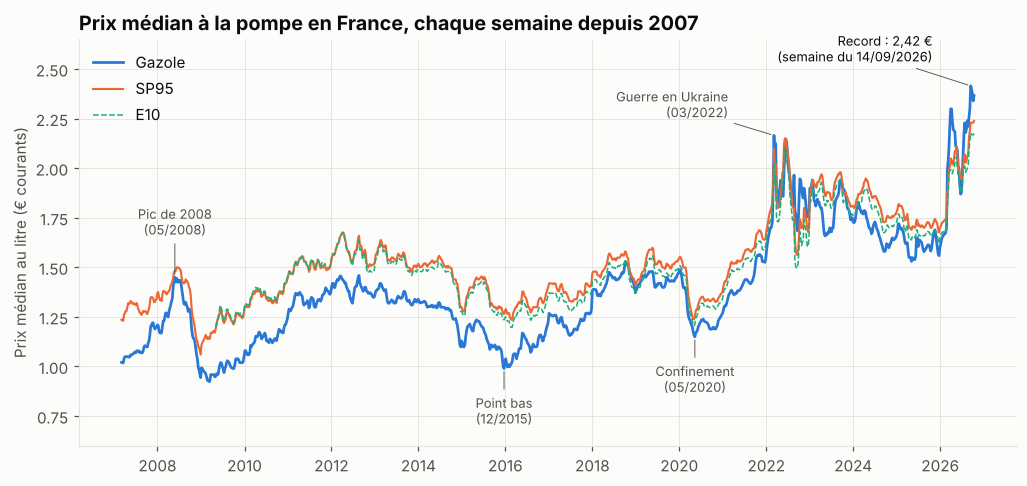

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for carburant, style in [("Gazole", {"linewidth": 1.8}), ("SP95", {"linewidth": 1.4}), ("E10", {"linewidth": 1, "linestyle": "--"})]:
    serie = stats.filter(carburant=carburant)
    ax.plot(serie["semaine"], serie["mediane"], color=COULEURS[carburant], label=carburant, **style)
# Extrêmes du gazole sur quelques périodes connues
evenements = [((2008, 2008), "max", "Pic de 2008"), ((2015, 2016), "min", "Point bas"),
              ((2020, 2020), "min", "Confinement"), ((2022, 2022), "max", "Guerre en Ukraine")]
for (debut, fin), sens, libelle in evenements:
    periode = gazole.filter(pl.col("semaine").dt.year().is_between(debut, fin)).sort("mediane")
    point = periode.row(-1 if sens == "max" else 0, named=True)
    ukraine = libelle == "Guerre en Ukraine"
    ax.annotate(f"{libelle}\n({point['semaine']:%m/%Y})", (point["semaine"], point["mediane"]),
                xytext=(-30, 12) if ukraine else (0, 28 if sens == "max" else -36), textcoords="offset points",
                ha="right" if ukraine else "center", fontsize=8.5, color=TEXTE_2,
                arrowprops={"arrowstyle": "-", "color": TEXTE_2, "lw": 0.6})
ax.annotate(f"Record : {record['mediane']:.2f} €\n(semaine du {record['semaine']:%d/%m/%Y})".replace(".", ",", 1),
            (record["semaine"], record["mediane"]), xytext=(-25, 14), textcoords="offset points", ha="right", va="bottom",
            fontsize=8.5, color=TEXTE, arrowprops={"arrowstyle": "-", "color": TEXTE_2, "lw": 0.6})
ax.set_ylim(0.6, 2.65)
ax.set_ylabel("Prix médian au litre (€ courants)")
ax.set_title("Prix médian à la pompe en France, chaque semaine depuis 2007")
ax.legend(frameon=False, labelcolor=TEXTE, loc="upper left")
axe_annees(ax)
sauver(fig, "06_vingt_ans_de_prix")

Le gazole est passé d'environ 1,10 € en moyenne en 2007 à 1,86 € en 2022, puis 2,07 € de janvier à mi-octobre 2026. Les grandes secousses se lisent directement : le pic de 2008, la chute de fin 2008, le point bas de fin 2015, le creux du confinement de 2020, puis la flambée de mars 2022.

**2026 bat les records en euros courants.** Le prix médian du gazole est passé de 1,70 € la semaine du 23 février à 2,30 € la semaine du 30 mars, soit 60 centimes en cinq semaines, puis a atteint 2,42 € à la mi-septembre, au-dessus du pic de 2022 (2,17 €). Ces données ne disent pas pourquoi : le notebook 03 confrontera ces prix au cours du Brent et au taux de change.

In [6]:
chiffres["hausse_printemps"] = chiffres["apres_hausse"] - chiffres["avant_hausse"]

### Sensibilité à la reconstruction

La série hebdomadaire dépend d'un choix : combien de temps prolonger un prix qui ne change pas. On compare la médiane du gazole obtenue avec une validité de 2, 4 (référence) ou 8 semaines, et avec les seuls prix publiés dans la semaine.

In [7]:
reference = gazole.select("semaine", reference="mediane")
variantes = {"publiés seuls": analyse.statistiques_hebdo(hebdo.filter(carburant="Gazole", publie=True))}
for validite in [2, 8]:
    variante = analyse.prix_hebdo(prix.filter(carburant="Gazole"), validite_semaines=validite)
    variantes[f"validité {validite} semaines"] = analyse.statistiques_hebdo(variante)
    del variante
ecarts = pl.DataFrame([
    {"variante": nom, **reference.join(v.select("semaine", "mediane"), on="semaine")
        .select(moyen=((pl.col("mediane") - pl.col("reference")).abs().mean() * 100).round(2),
                maximum=((pl.col("mediane") - pl.col("reference")).abs().max() * 100).round(2)).row(0, named=True)}
    for nom, v in variantes.items()
])
chiffres["sensibilite_moyenne"] = ecarts["moyen"].max()
chiffres["sensibilite_max"] = ecarts["maximum"].max()
ecarts

variante,moyen,maximum
str,f64,f64
"""publiés seuls""",0.55,2.0
"""validité 2 semaines""",0.23,1.0
"""validité 8 semaines""",0.14,1.0


Selon la variante, la médiane hebdomadaire s'écarte en moyenne d'au plus 0,6 centime de la référence, et de 2,0 centimes au pire, une semaine donnée. Les tendances et les ordres de grandeur ci-dessus n'en dépendent pas, mais une médiane hebdomadaire n'est pas précise au millième près : les prix sont arrondis au centime dans la suite.

## 2. Le gazole a perdu son avantage

In [8]:
ecart = (
    stats.filter(pl.col("carburant").is_in(["Gazole", "SP95", "E10"]))
    .pivot(on="carburant", index="semaine", values="mediane")
    .with_columns(sp95=(pl.col("Gazole") - pl.col("SP95")) * 100, e10=(pl.col("Gazole") - pl.col("E10")) * 100)
    .sort("semaine")
)
par_annee = ecart.group_by(annee=pl.col("semaine").dt.year()).agg(
    gazole_moins_sp95=pl.col("sp95").mean().round(1), gazole_moins_e10=pl.col("e10").mean().round(1)
).sort("annee")
for annee in [2008, 2011, 2016, 2018, 2022, 2026]:
    chiffres[f"ecart_sp95_{annee}"] = par_annee.filter(annee=annee)["gazole_moins_sp95"].item()
for annee in [2018, 2026]:
    chiffres[f"ecart_e10_{annee}"] = par_annee.filter(annee=annee)["gazole_moins_e10"].item()
chiffres["ecart_sp95_pic_2026"] = ecart.filter(pl.col("semaine").dt.year() == 2026)["sp95"].max()
par_annee

annee,gazole_moins_sp95,gazole_moins_e10
i32,f64,f64
2007,-20.1,null
2008,-10.1,null
2009,-22.5,-25.3
2010,-21.3,-22.4
2011,-17.1,-17.5
2012,-18.2,-17.0
2013,-19.8,-17.9
2014,-21.0,-18.4
2015,-21.8,-19.2


In [9]:
# Les hausses de taxes entrent en vigueur au 1er janvier : on compare l'évolution du gazole et du SP95 entre la semaine
# de Noël et la deuxième semaine de janvier. Les mouvements du marché touchent les deux ; un saut propre au gazole signe
# une hausse de taxe plus forte sur le gazole.
def lundi(jour):
    return jour - timedelta(days=jour.weekday())

sauts = []
for annee in range(2010, 2027):
    avant = ecart.filter(semaine=lundi(date(annee - 1, 12, 24)))
    apres = ecart.filter(semaine=lundi(date(annee, 1, 7)))
    if avant.height and apres.height:
        sauts.append({"annee": annee, "saut_gazole_moins_sp95": round(apres["sp95"].item() - avant["sp95"].item(), 1)})
sauts = pl.DataFrame(sauts)
for annee in [2015, 2016, 2017, 2018]:
    chiffres[f"saut_{annee}"] = sauts.filter(annee=annee)["saut_gazole_moins_sp95"].item()
chiffres["saut_hors_rattrapage"] = sauts.filter(~pl.col("annee").is_between(2015, 2018))["saut_gazole_moins_sp95"].abs().mean()
sauts

annee,saut_gazole_moins_sp95
i64,f64
2010,0.0
2011,0.8
2012,-0.5
2013,-1.9
2014,-0.5
2015,2.9
2016,2.5
2017,3.1
2018,4.8


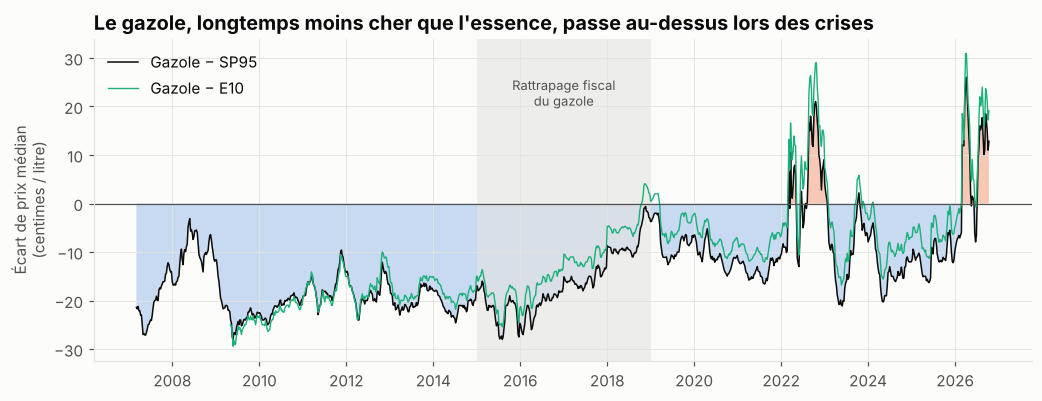

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.fill_between(ecart["semaine"], ecart["sp95"], 0, where=ecart["sp95"] < 0, color=BLEU, alpha=0.25, linewidth=0)
ax.fill_between(ecart["semaine"], ecart["sp95"], 0, where=ecart["sp95"] >= 0, color=ORANGE, alpha=0.35, linewidth=0)
ax.plot(ecart["semaine"], ecart["sp95"], color=TEXTE, linewidth=1, label="Gazole − SP95")
ax.plot(ecart["semaine"], ecart["e10"], color=AQUA, linewidth=0.9, label="Gazole − E10")
ax.axhline(0, color=TEXTE_2, linewidth=0.8)
ax.axvspan(date(2015, 1, 1), date(2019, 1, 1), color=GRILLE, alpha=0.6, linewidth=0)
ax.text(date(2017, 1, 1), ecart["sp95"].max(), "Rattrapage fiscal\ndu gazole", ha="center", va="top", fontsize=8.5, color=TEXTE_2)
ax.set_ylabel("Écart de prix médian\n(centimes / litre)")
ax.set_title("Le gazole, longtemps moins cher que l'essence, passe au-dessus lors des crises")
ax.legend(frameon=False, labelcolor=TEXTE, loc="upper left")
axe_annees(ax)
sauver(fig, "07_ecart_gazole_essence")

De 2009 à 2016, le gazole coûtait en moyenne 17 à 23 centimes de moins que le SP95 (l'écart était plus faible en 2008 : −10 centimes). De 2015 à 2018, la fiscalité du gazole a été alignée progressivement sur celle de l'essence (le « rattrapage »). Les données en gardent la trace : chaque début janvier de ces quatre années, le gazole prend 2,9, 2,5, 3,1 puis 4,8 centimes de plus que le SP95, contre 1,2 centime en moyenne (en valeur absolue) les autres années. L'écart annuel moyen se réduit en 2017-2018 et tombe à −8 centimes en 2018.

Lors des deux grandes crises, le gazole est passé **au-dessus** du SP95 : +3 centimes en moyenne en 2022, +7 en 2026, avec un pic à +26 centimes au printemps 2026. Comparé à l'E10, devenu l'essence la plus vendue, le gazole est encore plus souvent au-dessus : −3 centimes en 2018, +12 en 2026. L'ampleur de « l'avantage du gazole » dépend donc de l'essence prise pour référence.

## 3. Dispersion et prix identiques

In [11]:
# Part des stations au prix le plus fréquent de la semaine (prix en vigueur, prolongés compris)
def prix_modal(carburant):
    return (
        hebdo.filter(pl.col("carburant") == carburant, pl.col("semaine") >= DEBUT)
        .group_by("semaine", "prix").agg(n=pl.len())
        .sort("n", "prix")
        .group_by("semaine").agg(modal=pl.col("prix").last(), n_modal=pl.col("n").last(), n=pl.col("n").sum())
        .with_columns(part=pl.col("n_modal") / pl.col("n") * 100, carburant=pl.lit(carburant))
        .sort("semaine")
    )

modal = pl.concat([prix_modal("Gazole"), prix_modal("E10")])
modal_annuel = modal.with_columns(annee=pl.col("semaine").dt.year()).group_by("annee", "carburant").agg(
    part_moyenne=pl.col("part").mean().round(1), part_max=pl.col("part").max().round(1)
).sort("annee", "carburant").pivot(on="carburant", index="annee", values=["part_moyenne", "part_max"])
normal = modal_annuel.filter(pl.col("annee").is_between(2010, 2022))
chiffres["modal_gazole_min"], chiffres["modal_gazole_max"] = normal["part_moyenne_Gazole"].min(), normal["part_moyenne_Gazole"].max()
chiffres["modal_e10_min"], chiffres["modal_e10_max"] = normal["part_moyenne_E10"].min(), normal["part_moyenne_E10"].max()
for carburant in ["Gazole", "E10"]:
    for annee in [2023, 2026]:
        chiffres[f"modal_max_{carburant}_{annee}"] = modal_annuel.filter(annee=annee)[f"part_max_{carburant}"].item()
modal_annuel

annee,part_moyenne_Gazole,part_moyenne_E10,part_max_Gazole,part_max_E10
i32,f64,f64,f64,f64
2007,7.4,null,11.1,null
2008,6.1,null,11.3,null
2009,8.3,5.1,12.5,11.3
2010,7.6,4.3,9.9,6.0
2011,6.3,3.6,8.4,5.6
2012,6.4,3.8,9.1,5.5
2013,6.5,4.3,9.1,5.5
2014,6.4,4.7,8.2,6.8
2015,7.0,5.1,10.6,8.6


In [12]:
# Prix le plus fréquent du gazole en 2026, mois par mois
modal.filter(pl.col("carburant") == "Gazole", pl.col("semaine") >= date(2026, 1, 1)).group_by(mois=pl.col("semaine").dt.month()).agg(
    prix_le_plus_frequent=pl.col("modal").mode().first(), part_max=pl.col("part").max().round(1)).sort("mois")

mois,prix_le_plus_frequent,part_max
i8,f64,f64
1,1.629,9.2
2,1.659,7.1
3,2.09,24.7
4,2.25,18.6
5,2.09,22.6
6,1.899,9.3
7,2.25,12.4
8,2.25,20.0
9,2.25,22.7


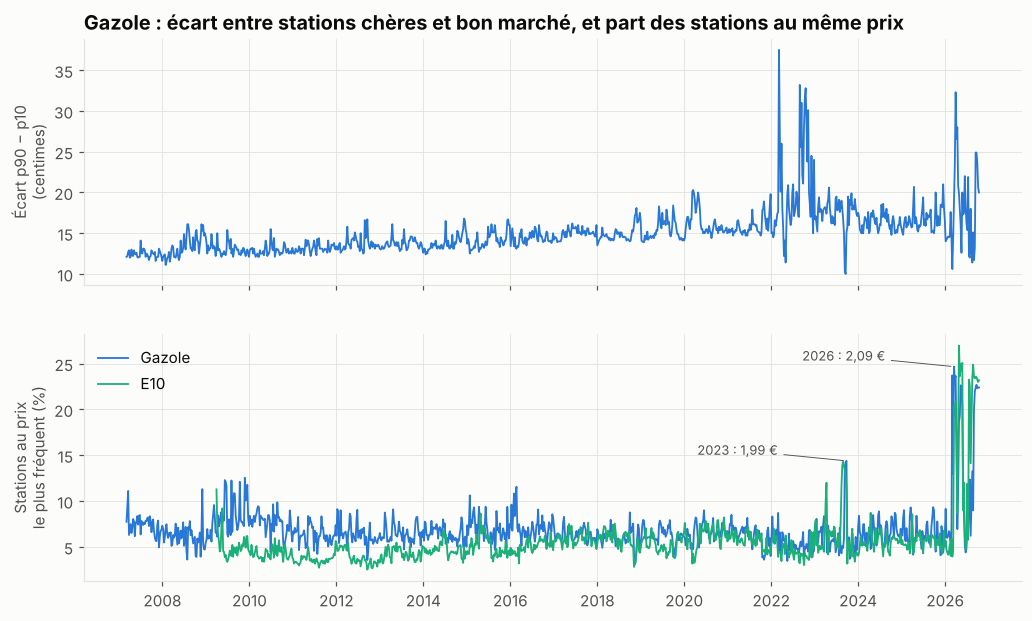

In [13]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6.4), sharex=True)
axes[0].plot(gazole["semaine"], (gazole["p90"] - gazole["p10"]) * 100, color=BLEU, linewidth=1.2)
axes[0].set_ylabel("Écart p90 − p10\n(centimes)")
axes[0].set_title("Gazole : écart entre stations chères et bon marché, et part des stations au même prix")
for carburant in ["Gazole", "E10"]:
    serie = modal.filter(carburant=carburant)
    axes[1].plot(serie["semaine"], serie["part"], color=COULEURS[carburant], linewidth=1.2, label=carburant)
    for annee in [2023, 2026]:
        pic = serie.filter(pl.col("semaine").dt.year() == annee).sort("part").row(-1, named=True)
        if carburant == "Gazole":
            axes[1].annotate(f"{annee} : {pic['modal']:.2f} €".replace(".", ","), (pic["semaine"], pic["part"]),
                             xytext=(-45, 4), textcoords="offset points", ha="right", fontsize=8.5, color=TEXTE_2,
                             arrowprops={"arrowstyle": "-", "color": TEXTE_2, "lw": 0.6})
axes[1].set_ylabel("Stations au prix\nle plus fréquent (%)")
axes[1].legend(frameon=False, labelcolor=TEXTE, loc="upper left")
axe_annees(axes[1])
sauver(fig, "08_dispersion_prix_ronds")

In [14]:
# Qui pratique ces prix identiques ? Enseigne OpenStreetMap (relevée en octobre 2026) des stations au prix le plus fréquent,
# la semaine du pic de 2023 et la dernière semaine de l'historique
enseignes = pl.read_parquet(sorted(Path("../data/enseignes").glob("stations_enseignes_*.parquet"))[-1]).select("station_id", "enseigne")

def qui(semaine, prix_rond):
    photo = hebdo.filter(carburant="Gazole", semaine=semaine).join(enseignes, on="station_id", how="left").with_columns(
        enseigne=pl.col("enseigne").fill_null("(inconnue)"), rond=pl.col("prix") == prix_rond)
    par_enseigne = photo.group_by("enseigne").agg(stations=pl.len(), au_prix=pl.col("rond").sum()).with_columns(
        part=(pl.col("au_prix") / pl.col("stations") * 100).round(1)).sort("stations", descending=True)
    total = par_enseigne.filter(enseigne="TotalEnergies").row(0, named=True)
    return par_enseigne, total["part"], total["au_prix"] / photo["rond"].sum() * 100

pic_2023 = modal.filter(carburant="Gazole").filter(pl.col("semaine").dt.year() == 2023).sort("part").row(-1, named=True)
derniere = hebdo["semaine"].max()
tables = {}
for nom, semaine, prix_rond in [("2023", pic_2023["semaine"], pic_2023["modal"]), ("2026", derniere, 2.25)]:
    tables[nom], chiffres[f"total_au_prix_{nom}"], chiffres[f"total_parmi_{nom}"] = qui(semaine, prix_rond)
print(f"Pic 2023 : semaine du {pic_2023['semaine']} à {pic_2023['modal']} € ; dernière semaine : {derniere}")
tables["2026"].head(12)

Pic 2023 : semaine du 2023-09-25 à 1.99 € ; dernière semaine : 2026-10-12


enseigne,stations,au_prix,part
str,u32,u32,f64
"""TotalEnergies""",1887,1763,93.4
"""(inconnue)""",1767,271,15.3
"""Intermarché""",1325,3,0.2
"""Carrefour""",1102,11,1.0
"""Système U""",649,2,0.3
"""E.Leclerc""",633,3,0.5
"""Esso""",551,11,2.0
"""Avia""",458,10,2.2
"""Auchan""",228,0,0.0


In [15]:
tables["2023"].head(8)

enseigne,stations,au_prix,part
str,u32,u32,f64
"""(inconnue)""",2548,288,11.3
"""TotalEnergies""",1653,949,57.4
"""Intermarché""",1206,2,0.2
"""Carrefour""",942,10,1.1
"""E.Leclerc""",609,21,3.4
"""Système U""",607,2,0.3
"""Esso""",532,9,1.7
"""Avia""",366,18,4.9


En temps normal (2010-2022), le prix le plus fréquent de la semaine ne concerne que 5 à 8 % des stations pour le gazole, 4 à 6 % pour l'E10. Deux épisodes sortent du lot :
- **2023** : jusqu'à 14 % des stations au même prix, 1,99 €, pour le gazole comme pour l'E10. TotalEnergies avait annoncé plafonner ses prix à 1,99 € le litre cette année-là. Les données le confirment en partie : la semaine du pic, 72 % des stations à 1,99 € sont des TotalEnergies, mais seulement 57 % des TotalEnergies sont à ce prix (les autres étaient en dessous du plafond).
- **2026** : jusqu'à 25 % des stations au même prix pour le gazole (2,09 € par épisodes au printemps, 2,25 € à partir de l'été) et 27 % pour l'E10 (1,99 €). La dernière semaine de l'historique (12 au 18 octobre), 93 % des stations TotalEnergies affichent le gazole à 2,25 €, et elles forment 84 % des stations à ce prix. Les données montrent un **prix uniforme** dans le réseau ; elles ne disent pas s'il s'agit d'un plafond annoncé.

Ce prix uniforme « écrase » le bas de la distribution : en 2026, le 10e centile du gazole reste collé à 2,25 €, d'où le creux de l'écart p90 − p10 dans le panneau du haut. L'enseigne TotalEnergies devra être traitée à part dans le modèle de prix (étape 5).

Hors de ces épisodes, l'écart entre les 10 % de stations les plus chères et les 10 % les moins chères est passé d'environ 13 centimes (2007-2012) à 16-18 centimes dans les années 2020, avec des pointes au-delà de 30 centimes au début des crises, quand toutes les stations ne répercutent pas la hausse au même rythme.

## 4. Géographie : des écarts stables, sauf en crise

In [16]:
stations = analyse.stations_connues(HISTORIQUE)
par_dep = analyse.statistiques_hebdo(
    hebdo.filter(pl.col("carburant") == "Gazole", pl.col("semaine") >= DEBUT)
    .join(stations.select(station_id="id", departement="departement"), on="station_id"),
    par=["departement"],
)
ecarts_dep = (
    par_dep.filter(pl.col("stations") >= 15, ~pl.col("departement").str.starts_with("97"))
    .join(gazole.select("semaine", national="mediane"), on="semaine")
    .with_columns(ecart=(pl.col("mediane") - pl.col("national")) * 100, annee=pl.col("semaine").dt.year())
    .group_by("departement", "annee").agg(pl.col("ecart").mean(), stations=pl.col("stations").mean())
)
matrice = ecarts_dep.pivot(on="annee", index="departement", values="ecart", sort_columns=True)
annees = [c for c in matrice.columns if c != "departement"]
matrice = matrice.with_columns(moyenne=pl.mean_horizontal(annees)).sort("moyenne").drop_nulls()

# Stabilité : corrélation de rang entre 2010 et 2025, avec un intervalle de confiance par bootstrap sur les départements
rangs = matrice.select(pl.col("2010").rank(), pl.col("2025").rank()).to_numpy()
generateur = np.random.default_rng(0)
tirages = [np.corrcoef(rangs[i].T)[0, 1] for i in (generateur.integers(0, len(rangs), len(rangs)) for _ in range(2000))]
chiffres["correlation_rangs"] = np.corrcoef(rangs.T)[0, 1]
chiffres["correlation_bas"], chiffres["correlation_haut"] = np.percentile(tirages, [2.5, 97.5])
dispersion = ecarts_dep.group_by("annee").agg(ecart_type=pl.col("ecart").std().round(2)).sort("annee")
for annee in [2021, 2022, 2025, 2026]:
    chiffres[f"dispersion_dep_{annee}"] = dispersion.filter(annee=annee)["ecart_type"].item()
for dep in ["75", "20"]:
    for annee in [2010, 2021, 2022, 2025, 2026]:
        chiffres[f"ecart_{dep}_{annee}"] = matrice.filter(departement=dep)[str(annee)].item()
chiffres["stations_paris_min"] = ecarts_dep.filter(departement="75")["stations"].min()
chiffres["stations_paris_max"] = ecarts_dep.filter(departement="75")["stations"].max()
print(f"Corrélation de rang 2010 / 2025 : {chiffres['correlation_rangs']:.2f} "
      f"(IC 95 % : {chiffres['correlation_bas']:.2f} à {chiffres['correlation_haut']:.2f})")
pl.concat([matrice.head(5), matrice.tail(5)]).select("departement", "2010", "2021", "2022", "2025", "2026", "moyenne").with_columns(
    pl.exclude("departement").round(1))

Corrélation de rang 2010 / 2025 : 0.76 (IC 95 % : 0.61 à 0.86)


departement,2010,2021,2022,2025,2026,moyenne
str,f64,f64,f64,f64,f64,f64
"""17""",-3.3,-2.8,-3.4,-3.7,-3.4,-3.6
"""79""",-2.9,-2.2,-2.5,-3.4,-2.7,-3.1
"""16""",-2.6,-1.7,-1.8,-2.9,-2.1,-2.7
"""44""",-1.9,-2.6,-3.8,-3.6,-3.4,-2.7
"""85""",-1.7,-2.7,-3.5,-3.4,-3.3,-2.5
"""06""",5.0,6.5,3.7,6.5,3.5,5.7
"""93""",4.5,11.1,6.9,8.2,2.6,6.4
"""20""",8.3,13.2,3.1,13.5,3.3,9.9
"""92""",7.5,14.3,10.8,13.6,4.7,10.2


In [17]:
dispersion.with_columns(pl.col("annee").cast(pl.Utf8)).transpose(include_header=False, column_names="annee")

2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2.07,2.29,2.31,2.22,2.19,2.57,2.52,2.62,2.63,2.61,3.0,2.91,2.95,3.26,3.27,2.38,3.36,3.37,3.44,1.89


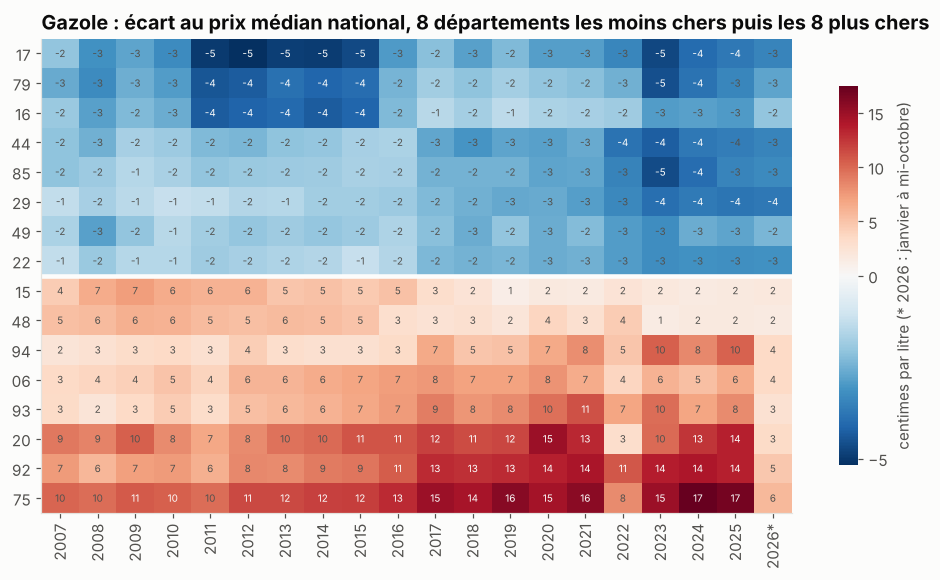

In [18]:
selection = pl.concat([matrice.head(8), matrice.tail(8)])
fig, ax = plt.subplots(figsize=(11, 5.6))
valeurs = selection.select(annees).to_numpy()
image = ax.imshow(valeurs, cmap="RdBu_r", norm=TwoSlopeNorm(vcenter=0, vmin=np.nanmin(valeurs), vmax=np.nanmax(valeurs)), aspect="auto")
for i in range(valeurs.shape[0]):
    for j in range(valeurs.shape[1]):
        intensite = image.norm(valeurs[i, j])
        ax.text(j, i, f"{valeurs[i, j]:.0f}", ha="center", va="center", fontsize=6.5,
                color=FOND if intensite < 0.15 or intensite > 0.8 else TEXTE_2)
ax.set_yticks(range(selection.height), selection["departement"])
ax.set_xticks(range(len(annees)), [a if a != "2026" else "2026*" for a in annees], rotation=90)
ax.axhline(7.5, color=FOND, linewidth=3)
ax.grid(False)
ax.set_title("Gazole : écart au prix médian national, 8 départements les moins chers puis les 8 plus chers")
barre = fig.colorbar(image, ax=ax, shrink=0.8, label="centimes par litre (* 2026 : janvier à mi-octobre)")
barre.outline.set_visible(False)
sauver(fig, "09_departements")

En temps normal, les écarts géographiques sont **stables** : la corrélation de rang entre les départements de 2010 et ceux de 2025 vaut 0,76 (intervalle de confiance à 95 % par bootstrap : 0,61 à 0,86). Les moins chers sont toujours sur la façade atlantique (Charente-Maritime, Deux-Sèvres, Charente, Loire-Atlantique, Vendée), quelques centimes sous la médiane nationale. Les plus chers sont Paris et la petite couronne, la Corse et les Alpes-Maritimes ; l'écart de Paris est passé de +10 centimes en 2010 à +17 en 2025 (Paris ne compte que 35 à 59 stations selon les années).

**Pendant les crises, les écarts se resserrent.** L'écart-type des écarts départementaux tombe de 3,3 centimes en 2021 à 2,4 en 2022, et de 3,4 en 2025 à 1,9 en 2026. La Corse, d'ordinaire 8 à 15 centimes au-dessus de la médiane, n'est qu'à +3 en 2022 et à +3 en 2026 ; Paris passe de +17 en 2025 à +6 en 2026. Deux explications sont possibles et ne sont pas départagées ici : des prix qui suivent les hausses plus lentement là où ils sont déjà hauts, et le poids des stations à prix uniforme (TotalEnergies), qui modifie la médiane nationale. C'est pourquoi la photo du 19 octobre (notebook 01) classait la Corse parmi les moins chères : un effet de crise, pas la situation habituelle.

## 5. Quel jour faire le plein ?

In [19]:
# Prix moyen en vigueur chaque jour (dernier prix publié, prolongé 6 jours au plus), puis écart à la moyenne mobile
# centrée sur 7 jours, qui retire la tendance de fond : il reste l'effet propre au jour de la semaine
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
effets = []
for annee in range(2018, 2026):
    jours = (
        prix.filter(pl.col("carburant") == "Gazole", pl.col("maj").dt.year().is_between(annee - 1, annee))
        .group_by("station_id", jour=pl.col("maj").dt.date()).agg(pl.col("prix").sort_by("maj").last())
        .collect()
        .sort("station_id", "jour")
        .upsample("jour", every="1d", group_by="station_id")
        .with_columns(pl.col("prix").forward_fill(limit=6).over("station_id"))
        .filter(pl.col("jour").dt.year() == annee)
        .drop_nulls("prix")
    )
    quotidien = jours.group_by("jour").agg(moyenne=pl.col("prix").mean()).sort("jour").with_columns(
        tendance=pl.col("moyenne").rolling_mean(7, center=True))
    effets.append(quotidien.drop_nulls().group_by(j=pl.col("jour").dt.weekday()).agg(
        effet=((pl.col("moyenne") - pl.col("tendance")) * 1000).mean()).with_columns(annee=pl.lit(annee)))
effets = pl.concat(effets)
synthese = effets.group_by("j").agg(
    moyenne=pl.col("effet").mean(), erreur=pl.col("effet").std() / pl.len().sqrt(), annees_negatives=(pl.col("effet") < 0).sum()
).sort("j").with_columns(jour=pl.col("j").replace_strict(range(1, 8), JOURS))
chiffres["effet_lundi"] = synthese.filter(j=1)["moyenne"].item()
chiffres["effet_mercredi"] = synthese.filter(j=3)["moyenne"].item()
chiffres["effet_vendredi"] = synthese.filter(j=5)["moyenne"].item()
chiffres["erreur_vendredi"] = synthese.filter(j=5)["erreur"].item()
chiffres["vendredi_negatif"] = synthese.filter(j=5)["annees_negatives"].item()
chiffres["annees_jour"] = effets["annee"].n_unique()
chiffres["mercredi_vendredi"] = (chiffres["effet_mercredi"] - chiffres["effet_vendredi"]) / 10
effets.pivot(on="j", index="annee", values="effet").rename(dict(zip(map(str, range(1, 8)), JOURS))).with_columns(pl.exclude("annee").round(2))

annee,vendredi,jeudi,mardi,lundi,samedi,mercredi,dimanche
i32,f64,f64,f64,f64,f64,f64,f64
2018,-1.52,1.1,0.57,0.2,-0.52,0.94,-0.28
2019,-0.81,1.14,1.56,0.79,-2.2,1.71,-2.27
2020,-1.32,0.22,0.5,0.71,-0.64,0.47,0.06
2021,-0.65,0.67,0.17,-0.23,-0.28,0.73,-0.74
2022,-0.93,2.86,-0.05,-2.58,-1.64,4.34,-1.99
2023,-4.08,2.49,2.21,0.94,-2.54,3.21,-1.68
2024,-1.98,0.59,0.77,0.56,-0.74,0.78,-0.19
2025,-2.38,0.92,0.89,0.63,-0.99,0.93,-0.02


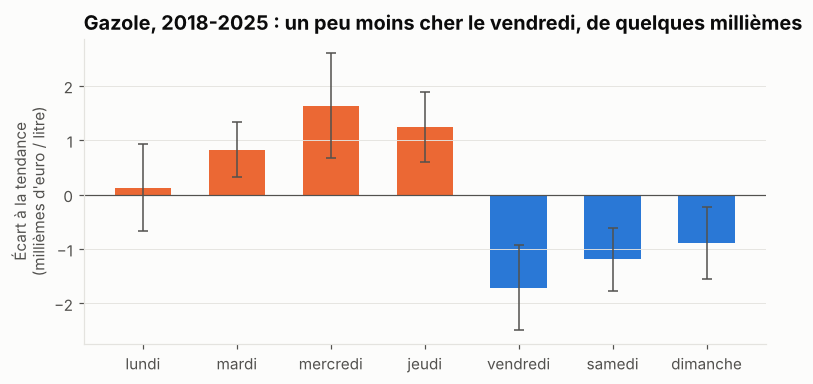

In [20]:
fig, ax = plt.subplots(figsize=(8, 3.6))
couleurs = [ORANGE if m > 0 else BLEU for m in synthese["moyenne"]]
ax.bar(synthese["jour"], synthese["moyenne"], yerr=1.96 * synthese["erreur"], color=couleurs, width=0.6,
       error_kw={"ecolor": TEXTE_2, "elinewidth": 1, "capsize": 3})
ax.axhline(0, color=TEXTE_2, linewidth=0.8)
ax.set_ylabel("Écart à la tendance\n(millièmes d'euro / litre)")
ax.set_title(f"Gazole, {effets['annee'].min()}-{effets['annee'].max()} : un peu moins cher le vendredi, de quelques millièmes")
ax.grid(axis="x", visible=False)
sauver(fig, "10_jour_de_la_semaine")

Une fois la tendance retirée, le gazole est en moyenne −1,7 millièmes d'euro sous sa tendance le vendredi (intervalle à 95 % : ± 0,8), et c'est le cas 8 années sur 8. Les prix sont au plus haut en milieu de semaine (+1,6 millièmes le mercredi) et le lundi est neutre (+0,1). L'effet existe mais il est **minuscule** : environ 0,3 centime par litre entre le mercredi et le vendredi, soit moins de 20 centimes sur un plein de 50 litres. Choisir sa station (13 à 28 centimes d'écart entre le premier et le dernier décile, notebook 01) compte 40 à 80 fois plus que choisir son jour.

## 6. Des prix qui bougent de plus en plus souvent

In [21]:
frequence = (
    prix.filter(pl.col("carburant") == "Gazole")
    .sort("station_id", "maj")
    .with_columns(delta=pl.col("prix") - pl.col("prix").shift(1).over("station_id"))
    .group_by(annee=pl.col("maj").dt.year())
    .agg(changements=(pl.col("delta") != 0).sum(), stations=pl.col("station_id").n_unique(),
         semaines=(pl.col("maj").max() - pl.col("maj").min()).dt.total_days() / 7)
    .with_columns(par_station_et_semaine=(pl.col("changements") / pl.col("stations") / pl.col("semaines")).round(2))
    .sort("annee")
    .collect()
)
for annee in [2022, 2025, 2026]:
    chiffres[f"frequence_{annee}"] = frequence.filter(annee=annee)["par_station_et_semaine"].item()
frequence.select("annee", "semaines", "par_station_et_semaine")

annee,semaines,par_station_et_semaine
i32,f64,f64
2007,52.0,0.87
2008,52.142857,1.44
2009,52.0,1.2
2010,52.0,1.15
2011,52.0,1.25
2012,52.142857,1.36
2013,52.0,1.27
2014,52.0,1.13
2015,52.0,1.37


Une station change le prix de son gazole un peu plus d'une fois par semaine en moyenne entre 2008 et 2020, et plus souvent depuis : 2,4 fois par semaine en 2022, 2,0 en 2025 et 2,1 sur les neuf premiers mois et demi de 2026. Les prix bougent davantage quand le pétrole est volatil, ce qui rend la collecte quotidienne d'autant plus utile.

## Limites

- **Prolongation des prix** : entre 18 et 29 % des prix hebdomadaires sont des prix prolongés, non republiés dans la semaine ; la sensibilité à ce choix est mesurée plus haut.
- **Composition du panel** : les stations entrent et sortent (environ 7 400 en 2007, près de 9 800 en 2026) ; une médiane nationale compare donc des ensembles de stations légèrement différents d'une année à l'autre.
- **Euros courants** : les prix ne sont pas corrigés de l'inflation ; en euros constants, le « record » de 2026 serait moins net face à 2008 ou 2012.
- **Enseignes** : l'enseigne vient d'OpenStreetMap, relevée en octobre 2026, et s'applique aux années passées comme si aucune station n'avait changé d'enseigne ; environ une station sur cinq n'en a pas.
- **2026** : l'année s'arrête mi-octobre.

## À retenir

- **2026 bat les records en euros courants** : le gazole a atteint 2,42 € à la mi-septembre, au-dessus du pic de 2022, après une hausse de 60 centimes en cinq semaines au printemps.
- **Le gazole a perdu son avantage** : nettement moins cher que l'essence jusqu'au rattrapage fiscal de 2015-2018, il passe au-dessus lors des crises de 2022 et 2026.
- **Les prix identiques de 2026 viennent de TotalEnergies** : 93 % de ses stations ont le gazole au même prix (2,25 €), ce qui déforme les statistiques nationales. L'enseigne sera une variable clé du modèle (étape 5).
- **La géographie est stable en temps normal** (façade atlantique bon marché ; Paris, Corse et Côte d'Azur chères), mais les écarts se resserrent pendant les crises : la photo d'un seul jour peut tromper.
- **Le jour du plein ne compte presque pas** (environ 0,3 centime entre le mercredi et le vendredi) ; la station, beaucoup.
- Prochaine étape : expliquer ces variations par le cours du Brent et l'euro, et mesurer si les prix montent plus vite qu'ils ne baissent (« fusée et plume »).

In [22]:
# Vérification : les chiffres cités dans le texte ci-dessus correspondent aux calculs de ce notebook.
# Ils sont aussi exportés pour le site.
CHIFFRES_JSON = Path('../rapports/chiffres_02.json')
CHIFFRES_JSON.write_text(json.dumps({k: round(float(v), 6) for k, v in sorted(chiffres.items())}, indent=1) + "\n")
CITES = {
 "gazole_2007": [
  1.098,
  0.005
 ],
 "gazole_2022": [
  1.862,
  0.005
 ],
 "gazole_2026": [
  2.068,
  0.005
 ],
 "avant_hausse": [
  1.699,
  0.005
 ],
 "apres_hausse": [
  2.299,
  0.005
 ],
 "hausse_printemps": [
  0.5999999999999999,
  0.005
 ],
 "record": [
  2.415,
  0.005
 ],
 "pic_2022": [
  2.165,
  0.005
 ],
 "sensibilite_moyenne": [
  0.55,
  0.05
 ],
 "sensibilite_max": [
  2.0,
  0.05
 ],
 "ecart_sp95_2008": [
  -10.1,
  0.5
 ],
 "saut_2015": [
  2.9,
  0.05
 ],
 "saut_2016": [
  2.5,
  0.05
 ],
 "saut_2017": [
  3.1,
  0.05
 ],
 "saut_2018": [
  4.8,
  0.05
 ],
 "saut_hors_rattrapage": [
  1.1923076923076923,
  0.05
 ],
 "ecart_sp95_2018": [
  -7.8,
  0.5
 ],
 "ecart_sp95_2022": [
  3.3,
  0.5
 ],
 "ecart_sp95_2026": [
  7.2,
  0.5
 ],
 "ecart_sp95_pic_2026": [
  25.99999999999998,
  0.5
 ],
 "ecart_e10_2018": [
  -3.4,
  0.5
 ],
 "ecart_e10_2026": [
  12.4,
  0.5
 ],
 "modal_gazole_min": [
  5.4,
  0.5
 ],
 "modal_gazole_max": [
  7.6,
  0.5
 ],
 "modal_e10_min": [
  3.6,
  0.5
 ],
 "modal_e10_max": [
  6.1,
  0.5
 ],
 "modal_max_Gazole_2023": [
  14.4,
  0.5
 ],
 "total_parmi_2023": [
  71.83951551854656,
  0.5
 ],
 "total_au_prix_2023": [
  57.4,
  0.5
 ],
 "modal_max_Gazole_2026": [
  24.7,
  0.5
 ],
 "modal_max_E10_2026": [
  27.0,
  0.5
 ],
 "total_au_prix_2026": [
  93.4,
  0.5
 ],
 "total_parmi_2026": [
  84.31372549019608,
  0.5
 ],
 "correlation_rangs": [
  0.755691218437308,
  0.005
 ],
 "correlation_bas": [
  0.6135514347390705,
  0.005
 ],
 "correlation_haut": [
  0.8564398899843675,
  0.005
 ],
 "ecart_75_2010": [
  10.479807692307693,
  0.5
 ],
 "ecart_75_2025": [
  16.71153846153846,
  0.5
 ],
 "stations_paris_min": [
  34.75609756097561,
  0.5
 ],
 "stations_paris_max": [
  59.320754716981135,
  0.5
 ],
 "dispersion_dep_2021": [
  3.27,
  0.05
 ],
 "dispersion_dep_2022": [
  2.38,
  0.05
 ],
 "dispersion_dep_2025": [
  3.44,
  0.05
 ],
 "dispersion_dep_2026": [
  1.89,
  0.05
 ],
 "ecart_20_2022": [
  3.113461538461539,
  0.5
 ],
 "ecart_20_2026": [
  3.282926829268294,
  0.5
 ],
 "ecart_75_2026": [
  5.717073170731712,
  0.5
 ],
 "effet_vendredi": [
  -1.7084036925315127,
  0.05
 ],
 "erreur_vendredi": [
  0.39748153835453276,
  0.025510204081632654
 ],
 "vendredi_negatif": [
  8.0,
  0.5
 ],
 "annees_jour": [
  8.0,
  0.5
 ],
 "effet_mercredi": [
  1.637109571911549,
  0.05
 ],
 "effet_lundi": [
  0.12718275841937732,
  0.05
 ],
 "mercredi_vendredi": [
  0.3345513264443062,
  0.05
 ],
 "frequence_2022": [
  2.4,
  0.05
 ],
 "frequence_2025": [
  2.05,
  0.05
 ],
 "frequence_2026": [
  2.15,
  0.05
 ],
 "prolongees_min": [
  17.6115447320457,
  0.5
 ],
 "prolongees_max": [
  29.03275204302989,
  0.5
 ]
}
ecarts_cites = {cle: (valeur, chiffres.get(cle)) for cle, (valeur, tolerance) in CITES.items()
                if chiffres.get(cle) is None or not abs(chiffres[cle] - valeur) <= tolerance}
assert not ecarts_cites, f"Chiffres du texte à mettre à jour : {ecarts_cites}"
print(f"{len(CITES)} chiffres cités, tous conformes aux calculs")

59 chiffres cités, tous conformes aux calculs
